In [1]:
# Imports
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("Qiskit Version:", qiskit.__version__)
simulator = AerSimulator()

def superdense_coding(message="00", bit_flip_error=False, shots=1024):
    if message not in {"00", "01", "10", "11"}:
        raise ValueError("Message must be 00, 01, 10, or 11")

    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)  # shared |Phi+> Bell pair
    qc.barrier()

    if message[0] == "1":
        qc.z(0)
    if message[1] == "1":
        qc.x(0)
    qc.barrier()

    if bit_flip_error:
        qc.x(0)

    qc.cx(0, 1)
    qc.h(0)
    qc.measure([0, 1], [0, 1])

    counts = simulator.run(qc, shots=shots).result().get_counts()
    return qc, counts


def decoded_counts(counts):
    # Convert Qiskit displayed c1c0 keys to message order.
    return {key[::-1]: value for key, value in counts.items()}


def decoded_message(counts):
    return max(decoded_counts(counts), key=decoded_counts(counts).get)


Qiskit Version: 2.5.1


Message: 00; counts: {'10': 2048}; accuracy: 0.00%
Message: 01; counts: {'00': 2048}; accuracy: 0.00%
Message: 10; counts: {'11': 2048}; accuracy: 0.00%
Message: 11; counts: {'01': 2048}; accuracy: 0.00%


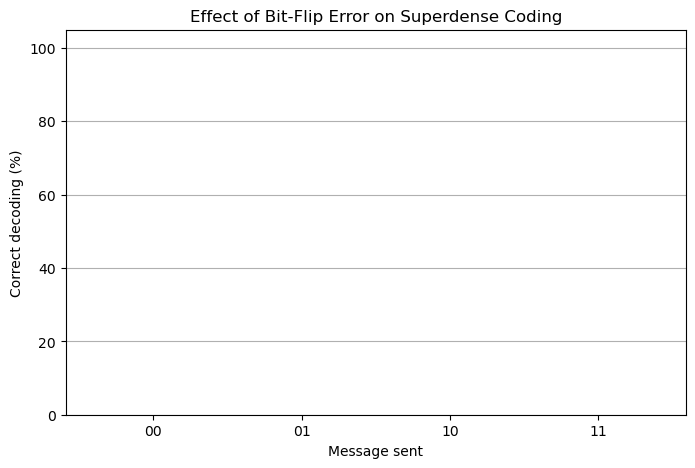

In [2]:
messages = ["00", "01", "10", "11"]
accuracy = []

for message in messages:
    _, counts = superdense_coding(message, bit_flip_error=True, shots=2048)
    corrected_order = decoded_counts(counts)
    acc = corrected_order.get(message, 0) / sum(counts.values())
    accuracy.append(acc)
    print(f"Message: {message}; counts: {counts}; accuracy: {acc*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.bar(messages, [a * 100 for a in accuracy])
plt.xlabel("Message sent")
plt.ylabel("Correct decoding (%)")
plt.title("Effect of Bit-Flip Error on Superdense Coding")
plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()
